In [3]:
import os, glob
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
print(os.listdir(path))
print(tf.config.list_physical_devices("GPU"))   # should show a GPU

['hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_images_part_1', 'ham10000_images_part_1', 'hmnist_8_8_L.csv', 'HAM10000_images_part_2', 'ham10000_images_part_2', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv']
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
df = pd.read_csv(os.path.join(path, "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv"))

# Images are split across two folders, so index every jpg by image_id
img_paths = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)}
df["path"] = df["image_id"].map(img_paths)
df = df.dropna(subset=["path"]).reset_index(drop=True)

classes = sorted(df["dx"].unique())          # akiec, bcc, bkl, df, mel, nv, vasc
class_to_idx = {c: i for i, c in enumerate(classes)}
df["label"] = df["dx"].map(class_to_idx)

print(df["dx"].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(gss.split(df, groups=df["lesion_id"]))
trainval_df, test_df = df.iloc[trainval_idx], df.iloc[test_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_idx, val_idx = next(gss2.split(trainval_df, groups=trainval_df["lesion_id"]))
train_df, val_df = trainval_df.iloc[train_idx], trainval_df.iloc[val_idx]

print(len(train_df), len(val_df), len(test_df))

7182 1306 1527


In [6]:
IMG_SIZE = 224
BATCH = 32
NUM_CLASSES = len(classes)
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, tf.one_hot(label, NUM_CLASSES)

def make_ds(dframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((dframe["path"].values, dframe["label"].values))
    if training:
        ds = ds.shuffle(2048, seed=42)
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

I0000 00:00:1790784082.930749      83 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790784082.933754      83 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [7]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weights = {i: w for i, w in enumerate(cw)}
print(class_weights)

{0: np.float64(4.539823008849558), 1: np.float64(2.795640326975477), 2: np.float64(1.2954545454545454), 3: np.float64(11.152173913043478), 4: np.float64(1.2857142857142858), 5: np.float64(0.2133499688084841), 6: np.float64(10.46938775510204)}


In [8]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augment")

base = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base.trainable = False   # Phase 1: frozen

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)                        # only active during training
x = base(x, training=False)                # EfficientNet has built-in preprocessing (expects 0-255)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

callbacks = [
    keras.callbacks.ModelCheckpoint("dermascan_best.keras", monitor="val_auc",
                                    mode="max", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                  patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
]

hist1 = model.fit(train_ds, validation_data=val_ds, epochs=10,
                  class_weight=class_weights, callbacks=callbacks)

Epoch 1/10


E0000 00:00:1790784108.711370      83 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


225/225 ━━━━━━━━━━━━━━━━━━━━ 51s 167ms/step - accuracy: 0.5007 - auc: 0.8238 - loss: 1.5173 - val_accuracy: 0.6210 - val_auc: 0.8776 - val_loss: 1.1797 - learning_rate: 0.0010
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.5671 - auc: 0.8616 - loss: 1.3437 - val_accuracy: 0.6417 - val_auc: 0.8991 - val_loss: 1.0791 - learning_rate: 0.0010
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.5759 - auc: 0.8747 - loss: 1.2330 - val_accuracy: 0.6493 - val_auc: 0.9056 - val_loss: 1.0429 - learning_rate: 0.0010
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.6074 - auc: 0.8909 - loss: 1.1150 - val_accuracy: 0.6639 - val_auc: 0.9165 - val_loss: 1.0052 - learning_rate: 0.0010
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.6217 - auc: 0.9020 - loss: 1.1432 - val_accuracy: 0.6876 - val_auc: 0.9327 - val_loss: 0.9029 - learning_rate: 0.0010
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.6220 - auc: 

In [12]:
print("Started")
base.trainable = True
for layer in base.layers[:-30]:          # keep early layers frozen
    layer.trainable = False
for layer in base.layers:                # keep BatchNorm frozen (important for stability)
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),   # much lower LR
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

hist2 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                  class_weight=class_weights, callbacks=callbacks)

Started
Epoch 1/15


E0000 00:00:1790784608.803879      83 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


225/225 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - accuracy: 0.6497 - auc: 0.9192 - loss: 0.9484 - val_accuracy: 0.7175 - val_auc: 0.9493 - val_loss: 0.7798 - learning_rate: 1.0000e-05
Epoch 2/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 23s 102ms/step - accuracy: 0.6455 - auc: 0.9209 - loss: 0.9690 - val_accuracy: 0.7060 - val_auc: 0.9479 - val_loss: 0.7893 - learning_rate: 1.0000e-05
Epoch 3/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 22s 99ms/step - accuracy: 0.6404 - auc: 0.9209 - loss: 0.9580 - val_accuracy: 0.7029 - val_auc: 0.9482 - val_loss: 0.7884 - learning_rate: 1.0000e-05
Epoch 4/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 22s 99ms/step - accuracy: 0.6514 - auc: 0.9258 - loss: 0.9726 - val_accuracy: 0.6968 - val_auc: 0.9480 - val_loss: 0.7871 - learning_rate: 3.0000e-06
Epoch 5/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 22s 98ms/step - accuracy: 0.6491 - auc: 0.9225 - loss: 0.9241 - val_accuracy: 0.6884 - val_auc: 0.9455 - val_loss: 0.8076 - learning_rate: 3.0000e-06


48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 146ms/step
              precision    recall  f1-score   support

       akiec       0.23      0.77      0.36        48
         bcc       0.52      0.42      0.47        66
         bkl       0.51      0.35      0.42       172
          df       0.21      0.70      0.32        10
         mel       0.42      0.37      0.39       186
          nv       0.89      0.84      0.86      1016
        vasc       0.66      0.79      0.72        29

    accuracy                           0.71      1527
   macro avg       0.49      0.61      0.50      1527
weighted avg       0.74      0.71      0.72      1527



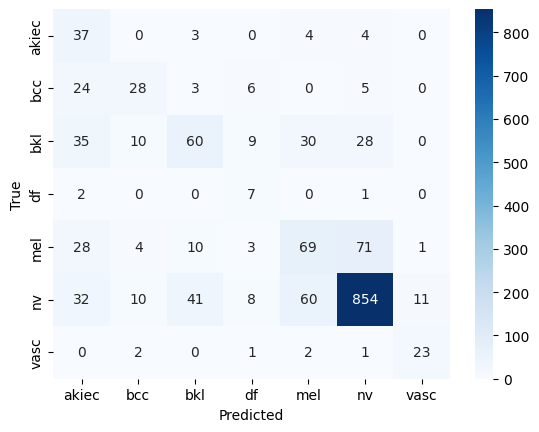

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

In [15]:
model.save("dermascan_final.keras")

def predict_image(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    probs = model.predict(tf.expand_dims(img, 0))[0]
    return {classes[i]: float(p) for i, p in sorted(enumerate(probs), key=lambda t: -t[1])}

print(predict_image(test_df.iloc[0]["path"]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
{'bkl': 0.7169022560119629, 'bcc': 0.12051894515752792, 'nv': 0.07398409396409988, 'mel': 0.050816815346479416, 'vasc': 0.027794407680630684, 'df': 0.006460638716816902, 'akiec': 0.003522778395563364}


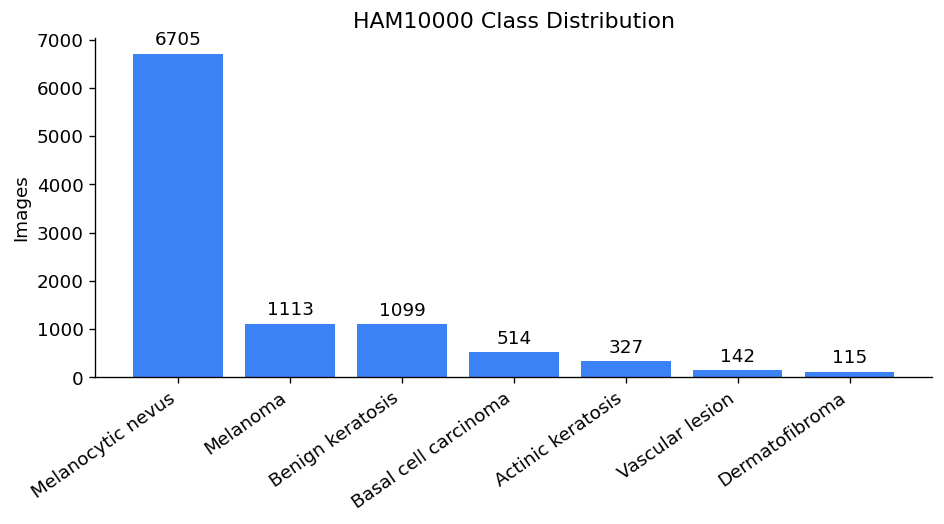

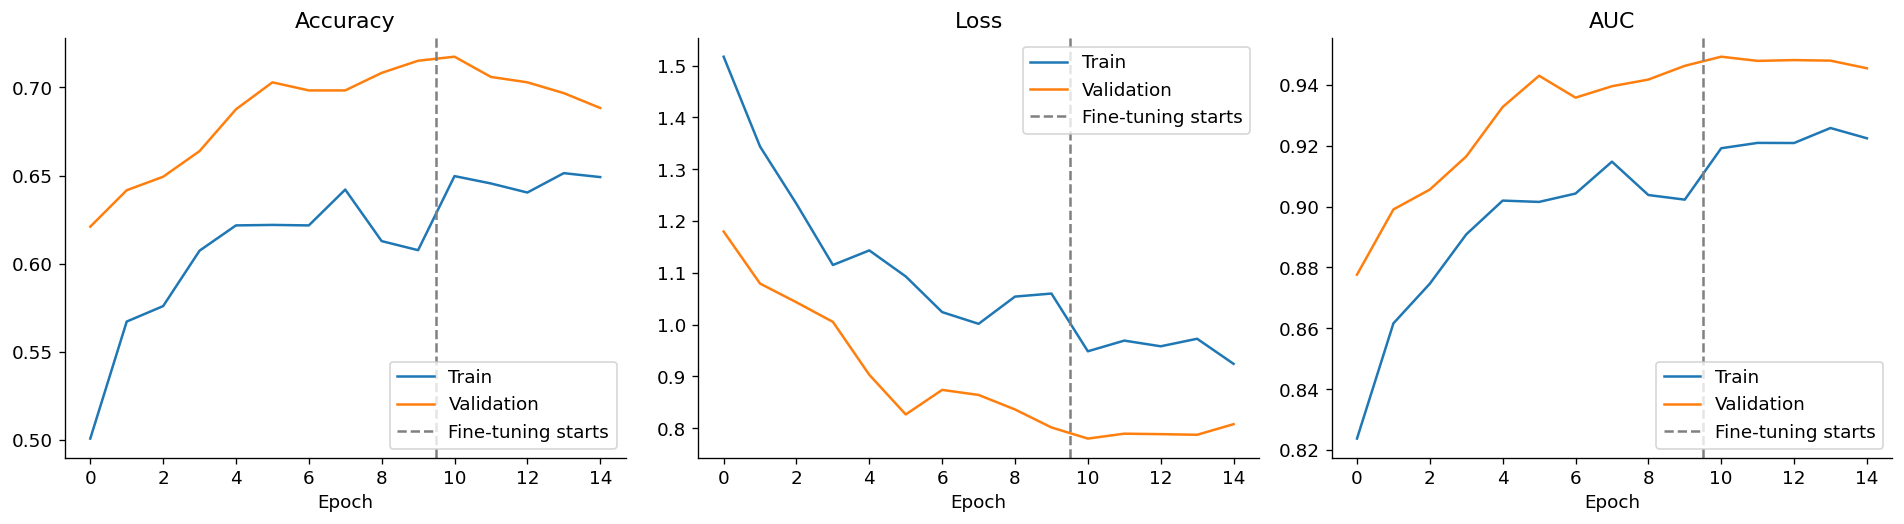

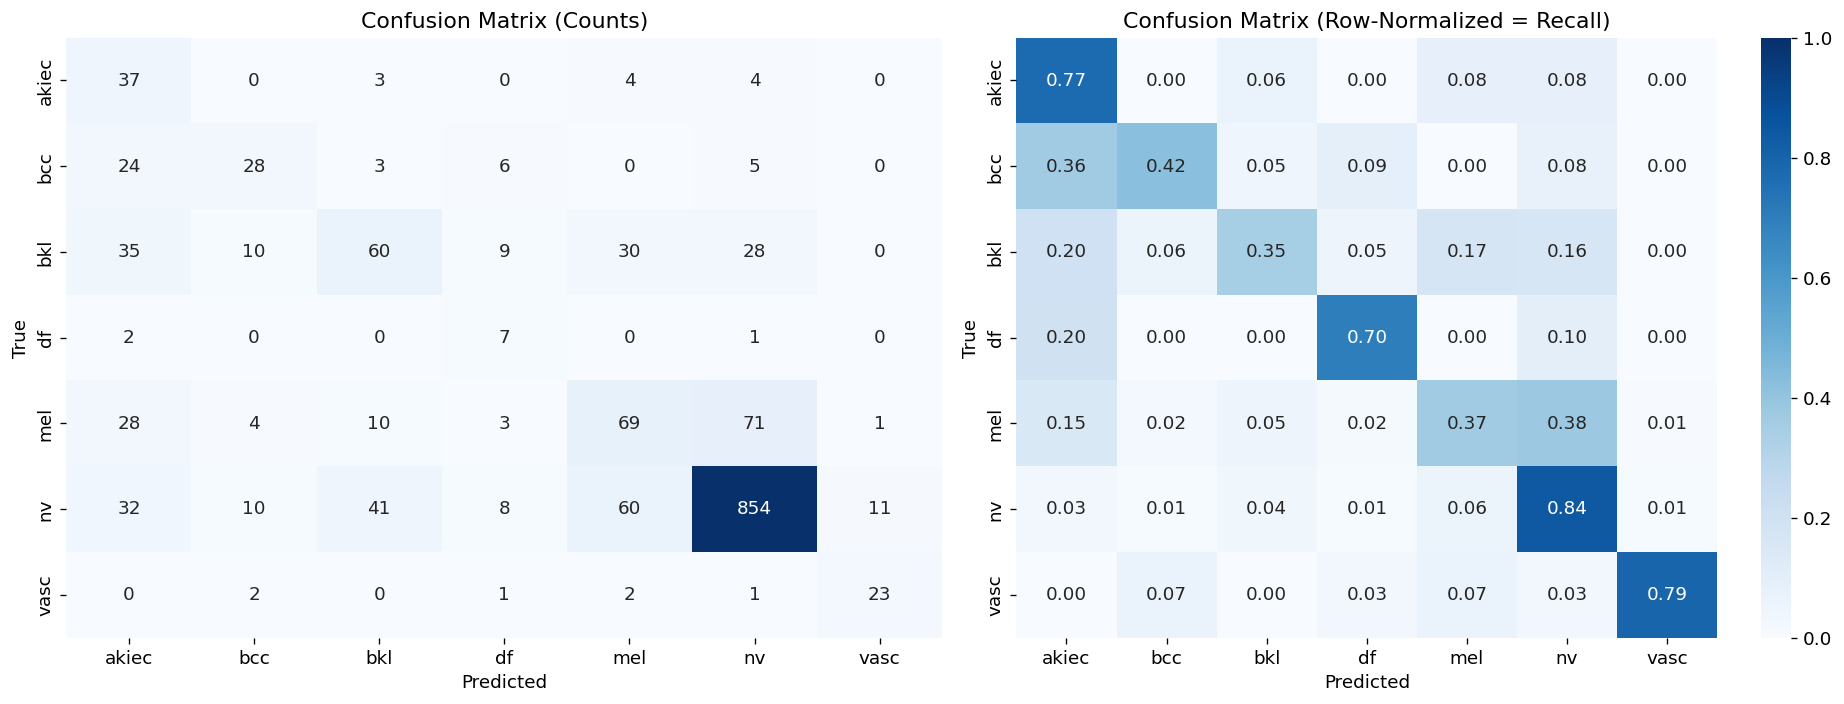

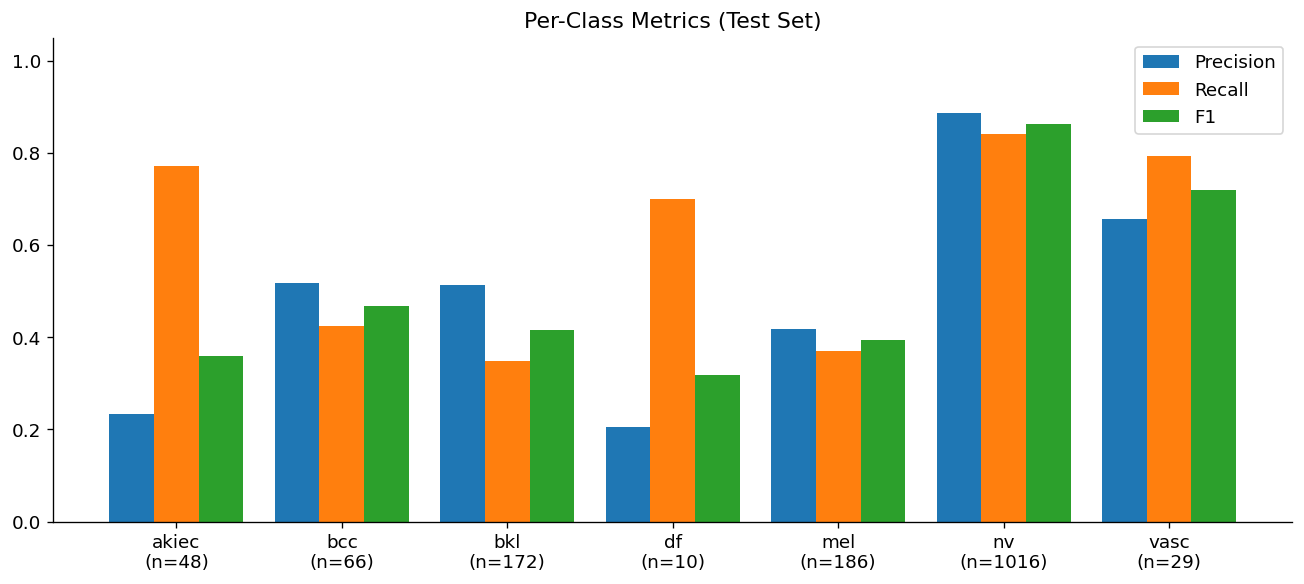

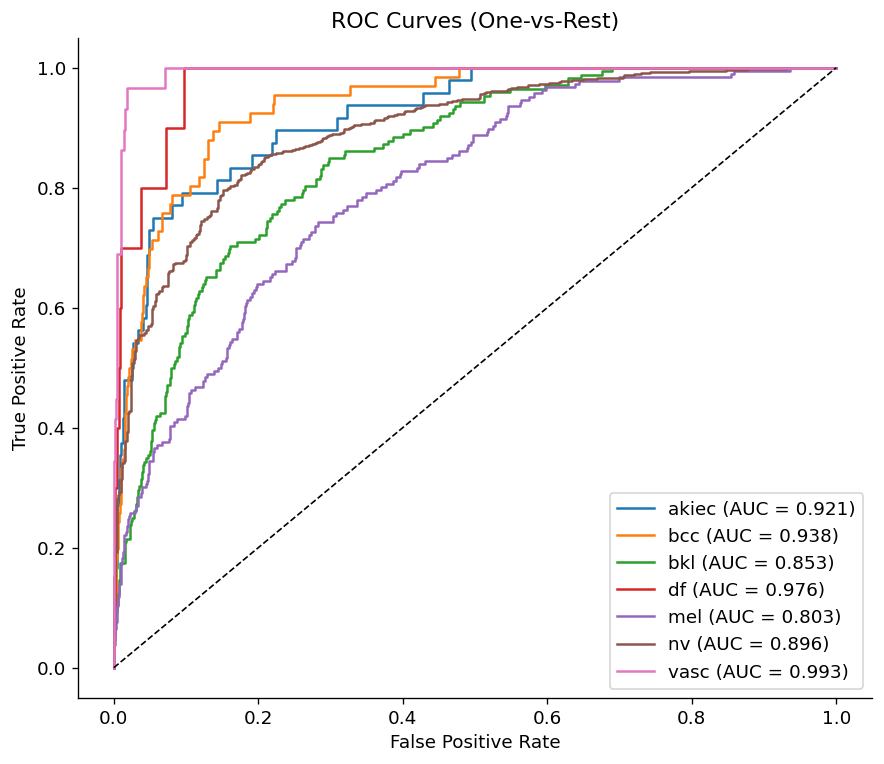

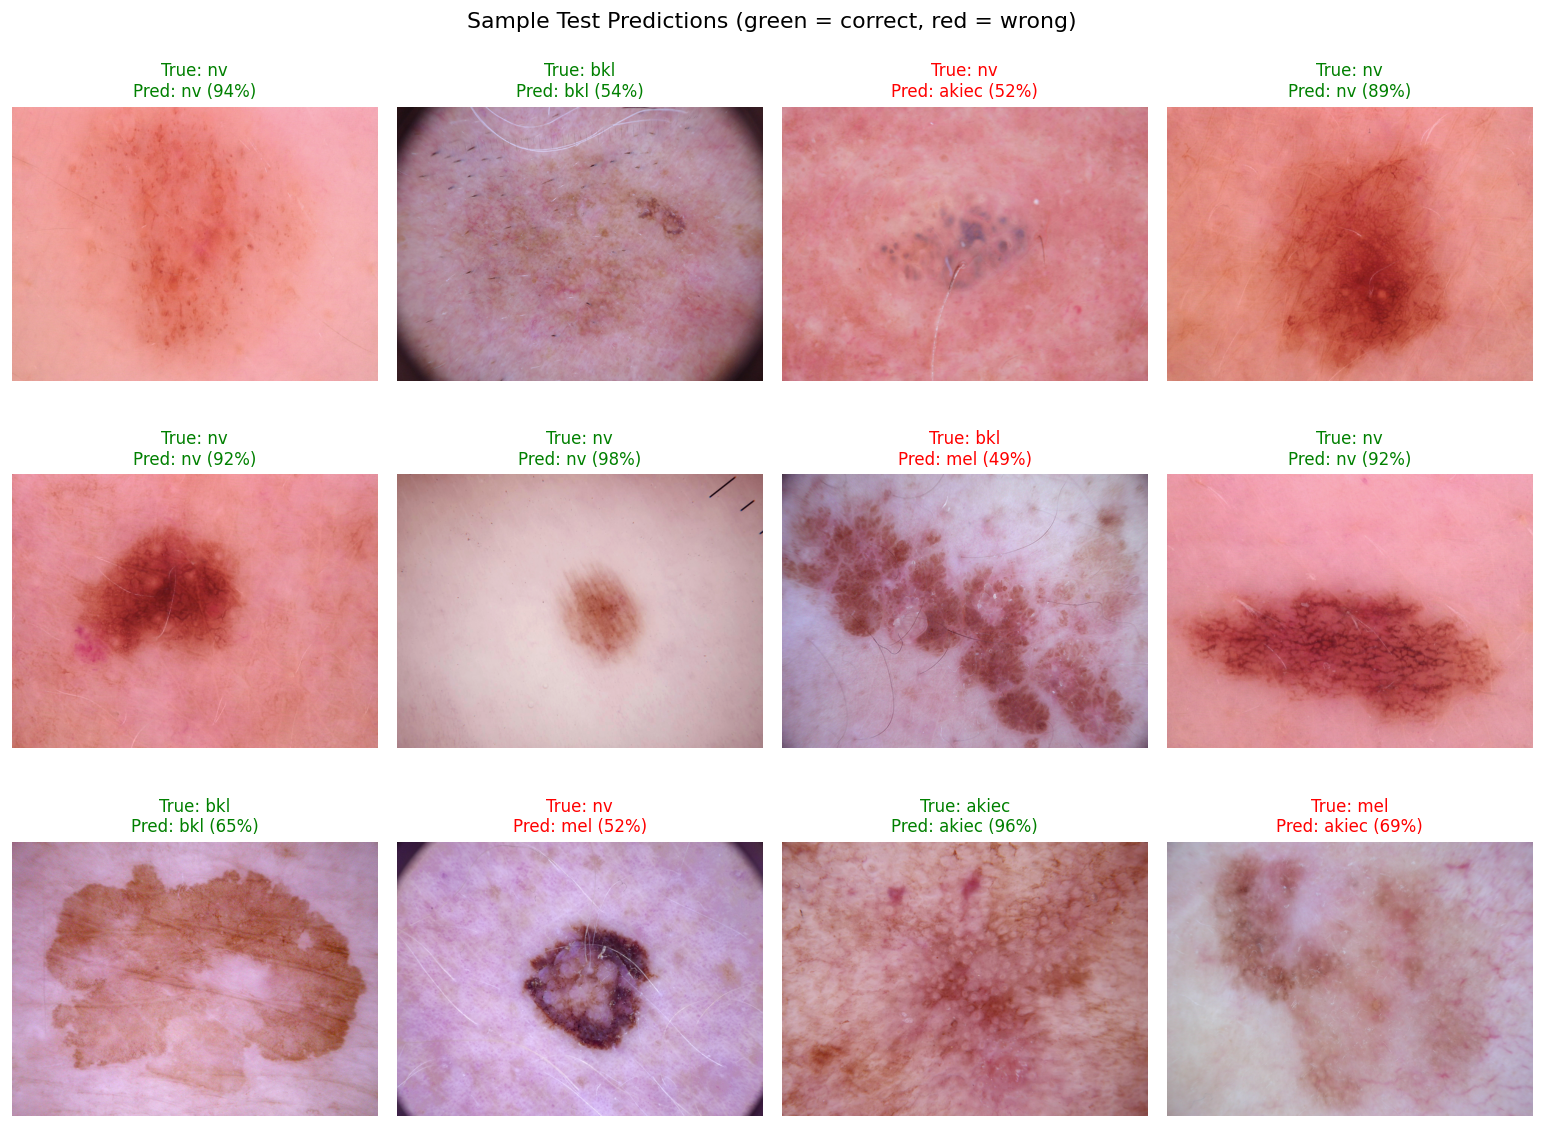

              precision    recall  f1-score   support

       akiec      0.234     0.771     0.359        48
         bcc      0.519     0.424     0.467        66
         bkl      0.513     0.349     0.415       172
          df      0.206     0.700     0.318        10
         mel      0.418     0.371     0.393       186
          nv      0.886     0.841     0.863      1016
        vasc      0.657     0.793     0.719        29

    accuracy                          0.706      1527
   macro avg      0.490     0.607     0.505      1527
weighted avg      0.742     0.706     0.716      1527

Macro AUC (OvR): 0.9112


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_curve, auc, precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT = "/kaggle/working"
full_names = {"akiec": "Actinic keratosis", "bcc": "Basal cell carcinoma",
              "bkl": "Benign keratosis", "df": "Dermatofibroma",
              "mel": "Melanoma", "nv": "Melanocytic nevus", "vasc": "Vascular lesion"}

# ---------- Predictions ----------
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))

# ---------- 1. Class distribution ----------
fig, ax = plt.subplots(figsize=(8, 4.5))
counts = df["dx"].value_counts()
bars = ax.bar([full_names[c] for c in counts.index], counts.values, color="#3b82f6")
ax.bar_label(bars, padding=3)
ax.set_title("HAM10000 Class Distribution"); ax.set_ylabel("Images")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT}/01_class_distribution.png"); plt.show()

# ---------- 2. Training curves (both phases) ----------
def joined(key):
    return hist1.history[key] + hist2.history[key]

split = len(hist1.history["loss"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (key, title) in zip(axes, [("accuracy", "Accuracy"), ("loss", "Loss"), ("auc", "AUC")]):
    ax.plot(joined(key), label="Train")
    ax.plot(joined(f"val_{key}"), label="Validation")
    ax.axvline(split - 0.5, color="gray", ls="--", label="Fine-tuning starts")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/02_training_curves.png"); plt.show()

# ---------- 3. Confusion matrices (counts + normalized) ----------
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes,
            yticklabels=classes, ax=axes[0], cbar=False)
axes[0].set_title("Confusion Matrix (Counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes,
            yticklabels=classes, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion Matrix (Row-Normalized = Recall)")
for ax in axes: ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{OUT}/03_confusion_matrices.png"); plt.show()

# ---------- 4. Per-class precision / recall / F1 ----------
p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(NUM_CLASSES))
x = np.arange(NUM_CLASSES); w = 0.27
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w, p, w, label="Precision")
ax.bar(x, r, w, label="Recall")
ax.bar(x + w, f1, w, label="F1")
ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={s})" for c, s in zip(classes, support)])
ax.set_ylim(0, 1.05); ax.set_title("Per-Class Metrics (Test Set)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/04_per_class_metrics.png"); plt.show()

# ---------- 5. ROC curves (one-vs-rest) ----------
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    ax.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves (One-vs-Rest)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/05_roc_curves.png"); plt.show()

# ---------- 6. Sample predictions ----------
rng = np.random.default_rng(42)
idxs = rng.choice(len(test_df), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, i in zip(axes.ravel(), idxs):
    ax.imshow(plt.imread(test_df.iloc[i]["path"])); ax.axis("off")
    ok = y_pred[i] == y_true[i]
    ax.set_title(f"True: {classes[y_true[i]]}\nPred: {classes[y_pred[i]]} ({y_prob[i].max():.0%})",
                 color="green" if ok else "red", fontsize=10)
plt.suptitle("Sample Test Predictions (green = correct, red = wrong)")
plt.tight_layout(); plt.savefig(f"{OUT}/06_sample_predictions.png"); plt.show()

# ---------- Text summary ----------
print(classification_report(y_true, y_pred, target_names=classes, digits=3))
print("Macro AUC (OvR):", round(np.mean([auc(*roc_curve(y_bin[:, i], y_prob[:, i])[:2])
                                         for i in range(NUM_CLASSES)]), 4))

In [1]:
import os
from IPython.display import FileLink

os.chdir("/kaggle/working")
FileLink("dermascan_best.keras")

/kaggle/working/dermascan_best.keras